In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

# Dataset collage

In [28]:
karpicko_img_list = [
    '../data/Karpicko/images/2024_08_12__12_25_00_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg',
    '../data/Karpicko/images/2024_08_15__13_55_00_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg',
    '../data/Karpicko/images/2024_08_16__16_25_00_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg',
    './images/2024_09_10__13_00_00_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg',
    './images/2024_10_11__13_00_00_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg',
    './images/2024_12_11__13_00_01_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg',
]

poznan_img_list = [
    '../data/Poznan/images/2024_10_19__09_00_00_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg',
    '../data/Poznan/images/2024_10_19__11_30_00_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg',
    '../data/Poznan/images/2024_10_20__14_30_00_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg',
    '../data/Poznan/images/2024_10_22__15_00_00_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg',
    '../data/Poznan/images/2024_10_22__15_30_00_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg',
    '../data/Poznan/images/2024_10_26__16_30_00_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg',
]

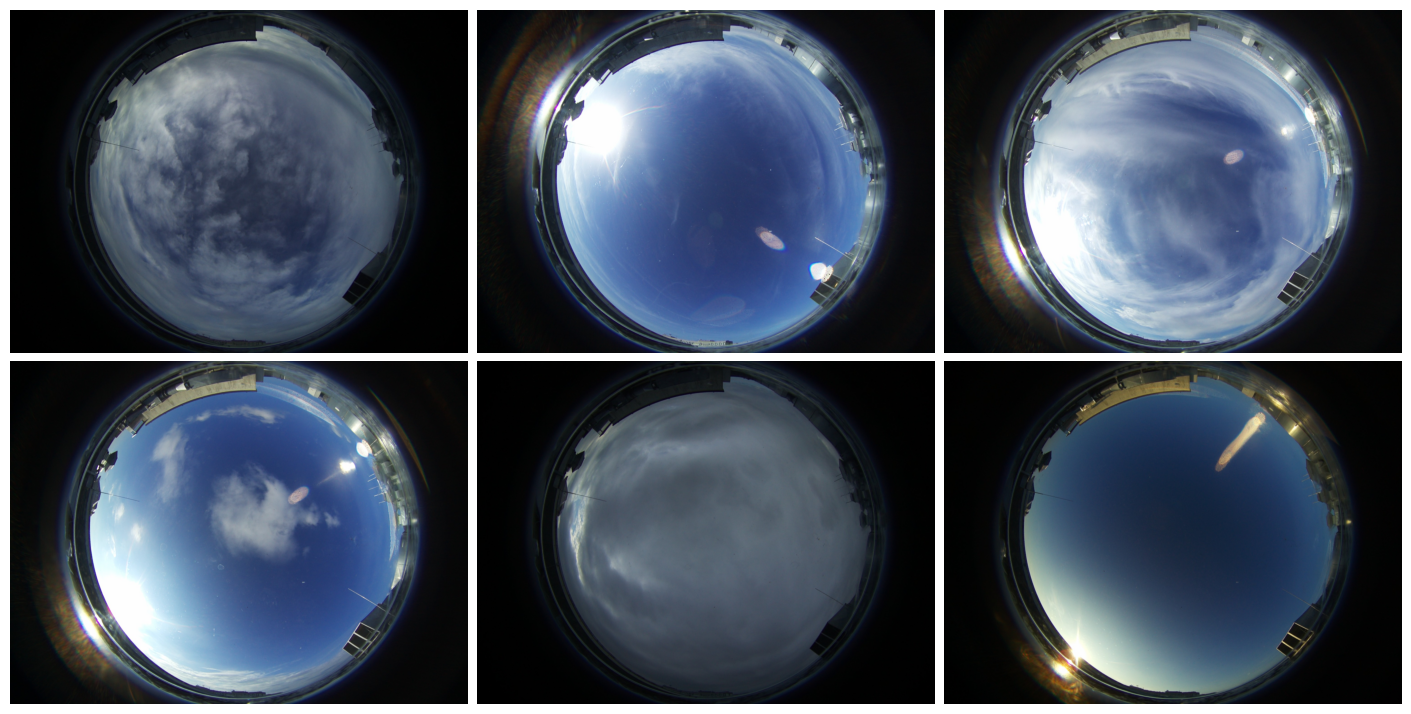

In [30]:
fig, ax = plt.subplots(2, 3, figsize=(14, 8), layout='compressed')

for idx, img_path in enumerate(poznan_img_list):
    img = np.asarray(Image.open(img_path))
    ax[idx//3][idx%3].imshow(img)
    ax[idx//3][idx%3].axis('off')


# plt.tight_layout()
# plt.show()
# plt.savefig('poznan-dataset.pdf', transparent=True, bbox_inches='tight', pad_inches=0)

# Sensor readings plot

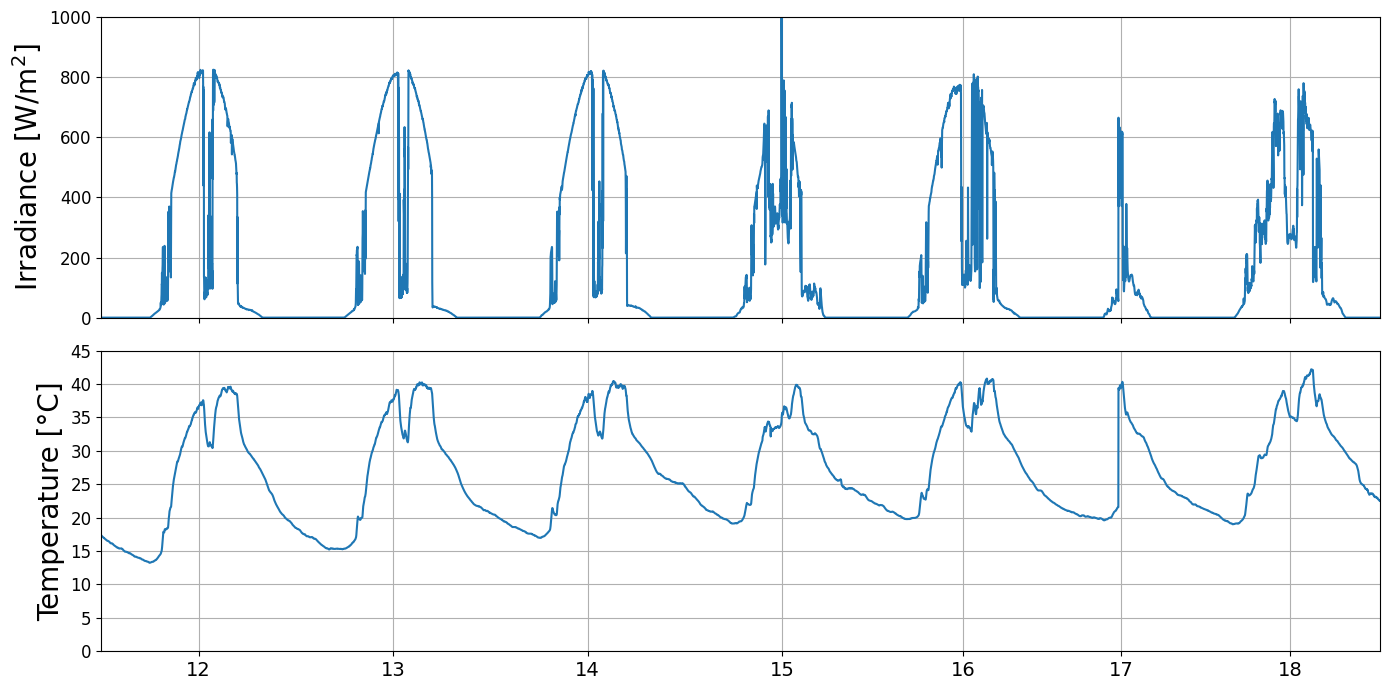

In [ ]:
df = pd.read_csv('../data/Karpicko/karpicko_irradiance.csv')

fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax[0].plot(df['irradiance'].values)
ax[0].grid(True)
ax[0].set_yticks(np.arange(0, 1000.1, 200), np.arange(0, 1000.1, 200).astype(int), fontsize=12)
ax[0].set_ylim([0, 1000])
ax[0].set_ylabel('Irradiance [W/m$^{2}$]', fontsize=20)
ax[1].plot(df['sensor_body_temperature'].values)
ax[1].grid(True)
ax[1].set_yticks(np.arange(0, 45.1, 5), np.arange(0, 45.1, 5).astype(int), fontsize=12)
ax[1].set_ylim([0, 45])
ax[1].set_xlim([0, len(df['sensor_body_temperature'].values)])
ax[1].set_xticks(
    [720, 2160, 3600, 5040, 6380, 7550, 8800],
    [12, 13, 14, 15, 16, 17, 18],
    fontsize=14,
)
ax[1].set_ylabel('Temperature [°C]', fontsize=20)
plt.tight_layout()
# plt.savefig('irradiance_temperature_karpicko.pdf', transparent=True, bbox_inches='tight', pad_inches=0)

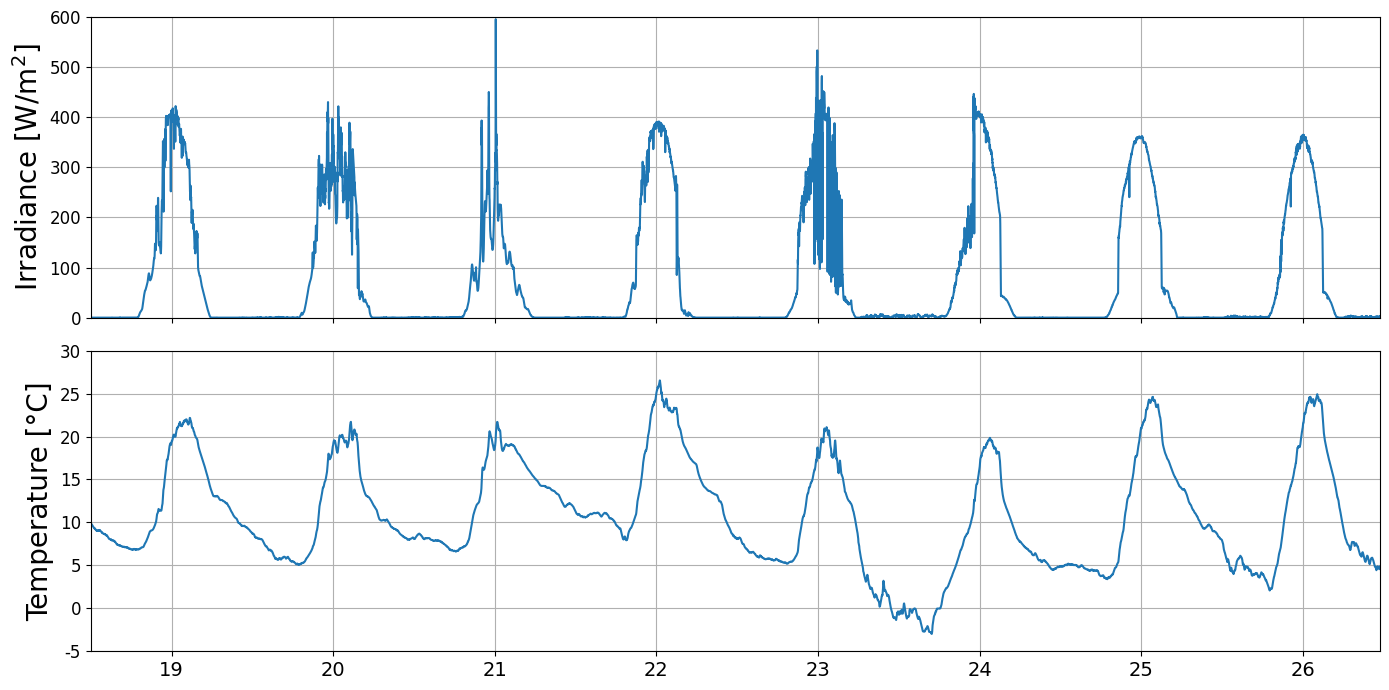

In [86]:
df = pd.read_csv('../data/Poznan/poznan_irradiance.csv')

fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax[0].plot(df['irradiance'].values)
ax[0].grid(True)
ax[0].set_yticks(np.arange(0, 600.1, 100), np.arange(0, 600.1, 100).astype(int), fontsize=12)
ax[0].set_ylim([0, 600])
ax[0].set_ylabel('Irradiance [W/m$^{2}$]', fontsize=20)
ax[1].plot(df['sensor_body_temperature'].values)
ax[1].grid(True)
ax[1].set_yticks(np.arange(-5, 30.1, 5), np.arange(-5, 30.1, 5).astype(int), fontsize=12)
ax[1].set_ylim([-5, 30])
ax[1].set_xlim([0, len(df['sensor_body_temperature'].values)])
ax[1].set_xticks(
    np.arange(720, len(df['sensor_body_temperature'].values), 1440),
    [19, 20, 21, 22, 23, 24, 25, 26],
    fontsize=14,
)
ax[1].set_ylabel('Temperature [°C]', fontsize=20)
plt.tight_layout()
plt.savefig('irradiance_temperature_poznan.pdf', transparent=True, bbox_inches='tight', pad_inches=0)

# Datasets sizes

In [2]:
karpicko_df = pd.read_csv('./karpicko_hukseflux_sr05-d1a3/karpicko_hukseflux_sr05-d1a3_irradiance.csv')
karpicko_samples = len(karpicko_df)
karpicko_day_samples = len(list(filter(lambda x: 5 <= int(x[12:14]) < 21, karpicko_df['datetime'].values)))
karpicko_night_samples = karpicko_samples - karpicko_day_samples

poznan_df = pd.read_csv('./poznan_hukseflux_sr05-d1a3/poznan_hukseflux_sr05-d1a3_irradiance.csv')
poznan_samples = len(poznan_df)
poznan_day_samples = len(list(filter(lambda x: 5 <= int(x[12:14]) < 21, poznan_df['datetime'].values)))
poznan_night_samples = poznan_samples - poznan_day_samples

datasets = {
    'Karpicko': {
        'Night samples (5-21)': karpicko_night_samples,
        'Day samples (5-21)': karpicko_day_samples,
    },
    'Poznan': {
        'Night samples (5-21)': poznan_night_samples,
        'Day samples (5-21)': poznan_day_samples,
    },
    'Modena': {
        'Night samples (5-21)': 3360,
        'Day samples (5-21)': 6150,
    }
}

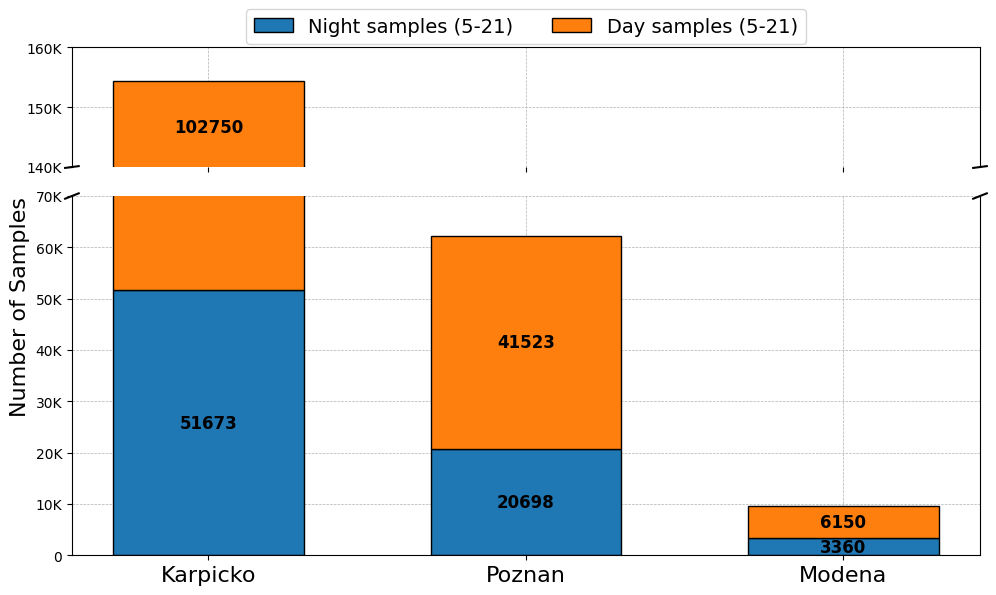

In [57]:
locations = datasets.keys()

# Ensure the necessary variables are defined
index = np.arange(len(locations))
bar_width = 0.6

plt.rc('axes', axisbelow=True)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [1, 3]})

# Create a stacked bar plot for the first axis (ax1)
bar1_ax1 = ax1.bar(index, night_samples, bar_width, label='Night samples (5-21)', color='tab:blue', edgecolor='black')
bar2_ax1 = ax1.bar(index, day_samples, bar_width, bottom=night_samples, label='Day samples (5-21)', color='tab:orange', edgecolor='black')
ax1.set_ylim(140000, 160000)
ax1.set_yticks(np.arange(140000, 160001, 10000), [f'{val//1000}K' for val in np.arange(140000, 160001, 10000)])
ax1.spines['bottom'].set_visible(False)
ax1.tick_params(labeltop=False)  # don't put tick labels at the top
ax1.grid(True, which='both', axis='both', linestyle='--', linewidth=0.5)

# Create a stacked bar plot for the second axis (ax2)
bar1_ax2 = ax2.bar(index, night_samples, bar_width, label='Night samples (5-21)', color='tab:blue', edgecolor='black')
bar2_ax2 = ax2.bar(index, day_samples, bar_width, bottom=night_samples, label='Day samples (5-21)', color='tab:orange', edgecolor='black')
ax2.set_ylim(0, 70000)
ax2.set_yticks(np.arange(0, 70001, 10000), [f'{val//1000}K' if val else f'{val//1000}' for val in np.arange(0, 70001, 10000)])
ax2.spines['top'].set_visible(False)
ax2.grid(True, which='both', axis='both', linestyle='--', linewidth=0.5)

for _bar1, _bar2 in zip(bar1_ax1[:1], bar2_ax1[:1]):
    height = _bar2.get_height()
    ax1.text(
        _bar2.get_x() + _bar2.get_width() / 2,
        _bar1.get_height() + height * 0.925,
        f'{height}',
        ha='center',
        va='center',
        color='black',
        fontsize=12,
        fontweight='bold',
    )

# # add values on center of the bars for ax2
for bar in bar1_ax2:
    height = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        height / 2,
        f'{height}',
        ha='center',
        va='center',
        color='black',
        fontsize=12,
        fontweight='bold',
    )

for _bar1, _bar2 in zip(bar1_ax2[1:], bar2_ax2[1:]):
    height = _bar2.get_height()
    ax2.text(
        _bar2.get_x() + _bar2.get_width() / 2,
        _bar1.get_height() + height / 2,
        f'{height}',
        ha='center',
        va='center',
        color='black',
        fontsize=12,
        fontweight='bold',
    )

ax2.set_ylabel('Number of Samples', loc='top', fontsize=16)
ax2.set_xticks(index)
ax2.set_xticklabels(locations, fontsize=16)

# move legend above graph and use ncol=2
ax1.legend(ncol=2, loc='upper center', bbox_to_anchor=(0.5, 1.4), fontsize=14)

plt.tight_layout()

# Add broken axis effect
d = .0075  # how big to make the diagonal lines in axes coordinates
kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False)
ax1.plot((-d, +d), (-d, +d), **kwargs)        # top-left diagonal
ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax2.transAxes)  # switch to the bottom axes
ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)  # bottom-left diagonal
ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)  # bottom-right diagonal

plt.savefig('samples_per_dataset.pdf', transparent=True, bbox_inches='tight', pad_inches=0)